# **QSAR Model Building of Acetylcholinesterase Inhibitors**

Chanin Nantasenamat

*Data Professor YouTube channel, http://youtube.com/dataprofessor*

# Read in data

In [1]:
import pandas as pd

In [2]:
! ls


bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv
descriptors_output.csv
requirements.txt
sample_data


In [3]:
# Load your local KEAP1 bioactivity dataset
dataset_path = 'bioactivity_preprocessed_data_keap1_3class_pIC50_pubchem_fp.csv'
dataset = pd.read_csv(dataset_path)

# Display the dataset
dataset


,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880,pIC50
0,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.568636
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,3.928118
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.481486
3,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.769551
4,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.698970
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,8.113509
342,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.853872
343,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,7.508638
344,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,5.000000


In [4]:
X = dataset.drop(['pIC50'], axis=1)
X

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP3,PubchemFP4,PubchemFP5,PubchemFP6,PubchemFP7,PubchemFP8,PubchemFP9,...,PubchemFP871,PubchemFP872,PubchemFP873,PubchemFP874,PubchemFP875,PubchemFP876,PubchemFP877,PubchemFP878,PubchemFP879,PubchemFP880
0,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
342,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
343,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
344,1,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [5]:
Y = dataset.iloc[:,-1]
Y

,pIC50
0,5.568636
1,3.928118
2,7.481486
3,5.769551
4,7.698970
...,...
341,8.113509
342,5.853872
343,7.508638
344,5.000000


# Remove low variance features

In [6]:
from sklearn.feature_selection import VarianceThreshold

def remove_low_variance(input_data, threshold=0.1):
    selection = VarianceThreshold(threshold)
    selection.fit(input_data)
    return input_data[input_data.columns[selection.get_support(indices=True)]]

X = remove_low_variance(X, threshold=0.1)
X

,PubchemFP0,PubchemFP1,PubchemFP2,PubchemFP13,PubchemFP16,PubchemFP17,PubchemFP21,PubchemFP22,PubchemFP23,PubchemFP33,...,PubchemFP783,PubchemFP791,PubchemFP797,PubchemFP798,PubchemFP800,PubchemFP812,PubchemFP818,PubchemFP820,PubchemFP821,PubchemFP825
0,1,1,1,0,0,0,0,0,0,1,...,1,1,0,0,1,0,1,0,1,0
1,1,1,1,0,0,0,0,0,1,1,...,0,0,1,0,0,0,0,1,1,0
2,1,1,1,1,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,1,1,0,0,0,0,0,0,1,...,1,1,0,0,1,0,1,0,1,0
4,1,1,1,0,0,0,1,0,0,1,...,1,1,0,0,1,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,1,1,1,0,0,0,1,0,0,1,...,1,1,0,0,1,0,1,0,1,0
342,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
343,1,0,0,1,1,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
344,1,1,1,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0


In [7]:
X.to_csv('descriptor_list.csv', index = False)

In [8]:
# In the app, use the following to get this same descriptor list
# of 218 variables from the initial set of 881 variables
# Xlist = list(pd.read_csv('descriptor_list.csv').columns)
# X[Xlist]

# Gradient Boosting Regressor Model

In [9]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the Gradient Boosting Regressor Model
model = GradientBoostingRegressor(n_estimators=500, random_state=42)

# Train the model
model.fit(X, Y)

# Calculate and display the R² score on training data
r2 = model.score(X, Y)
print(f"R2 Score: {r2}")

# Make predictions
Y_pred = model.predict(X)
Y_pred


R2 Score: 0.8721830796688494


array([5.70908407, 3.98169606, 7.15837941, 5.70908407, 7.42174998,
       5.69941323, 3.71868231, 7.30061006, 6.27593674, 6.77601155,
       6.44888849, 5.40619591, 4.06025567, 2.95964968, 6.42871875,
       6.18465895, 5.24705009, 6.76524866, 7.20516007, 7.20516007,
       8.12979047, 7.45306263, 7.0592125 , 5.85633112, 6.07660944,
       5.99336025, 5.85633112, 5.85633112, 7.23633047, 6.65958703,
       6.67096289, 6.81200232, 6.53838059, 6.65724968, 6.70042164,
       6.71329193, 5.70908407, 7.42174998, 5.63750431, 5.47904654,
       4.65221837, 4.11036215, 5.9200304 , 5.80869468, 5.09502462,
       6.07660944, 7.20516007, 7.23633047, 7.23633047, 7.95327568,
       7.20516007, 7.20516007, 5.36228785, 4.89667568, 5.2219887 ,
       4.90929424, 6.35142607, 4.90929424, 6.35142607, 5.21612281,
       5.21612281, 5.17842418, 5.41569114, 5.17842418, 5.17842418,
       5.01922271, 6.07893609, 5.29862539, 6.16624151, 4.12729182,
       4.52373789, 5.3175854 , 5.92058404, 4.55241338, 5.86296

## Model Prediction

## Model Performance

In [10]:
print('Mean squared error (MSE): %.2f'
      % mean_squared_error(Y, Y_pred))
print('Coefficient of determination (R^2): %.2f'
      % r2_score(Y, Y_pred))

Mean squared error (MSE): 0.23
Coefficient of determination (R^2): 0.87


# Data Visualization (Experimental vs Predicted pIC50 for Training Data)

In [11]:
import matplotlib.pyplot as plt
import numpy as np

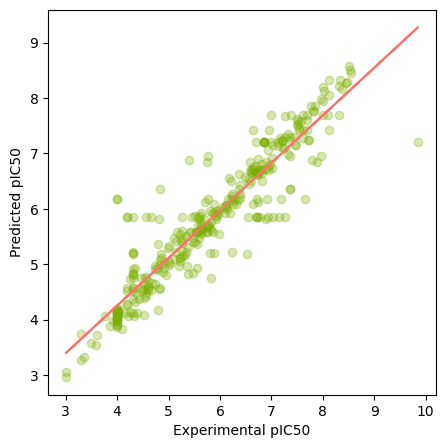

In [15]:
plt.figure(figsize=(5,5))
plt.scatter(x=Y, y=Y_pred, c="#7CAE00", alpha=0.3)

# Add trendline
# https://stackoverflow.com/questions/26447191/how-to-add-trendline-in-python-matplotlib-dot-scatter-graphs
z = np.polyfit(Y, Y_pred, 1)
p = np.poly1d(z)

plt.plot(Y,p(Y),"#F8766D")
plt.ylabel('Predicted pIC50')
plt.xlabel('Experimental pIC50')
# Save the plot as a 600 DPI PNG image
plt.savefig('keap1_experimental_vs_predicted_pIC50.png', dpi=600, bbox_inches='tight')

# Display the plot in the notebook
plt.show()

# Save Model as Pickle Object

In [13]:
import pickle

In [14]:
pickle.dump(model, open('acetylcholinesterase_model.pkl', 'wb'))